**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: José Carlos Sierra Pére
*   MATRÍCULA: A01055689

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm



1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [ ]:
loan_df = pd.read_csv('personal_loan.csv', index_col='ID')
loan_df.head()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1


In [ ]:
print(len(loan_df))

5037


In [ ]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


**Respuesta:** El dataframe tiene 5,037 registros y 13 columnas (sin contar `ID`, que quedó como índice).
* **8 columnas numéricas:** `Age`, `Experience`, `Income`, `ZIP Code`, `Family`, `Mortgage` (int64) y `CCAvg`, `Education` (float64).
* **5 columnas de texto (object):** `Personal Loan`, `Securities Account`, `CD Account`, `Online` y `CreditCard`. Son variables binarias, pero pandas las leyó como texto porque mezclan formatos (`Yes`/`No` y `1`/`0`).

`Education` aparece como float porque contiene un valor no entero (7.3), (deduciendo por la lectura de las instrucciones de la tarea esto ya indica un dato inválido.)

Esto no estaba en la tarea, pero pense en agregarlo: 

Revisión previa de los valores

Para decidir sobre los criterios,  a mí me gusta ver algunas cosas generales de los valores. Esto no estaba tal cual en la tarea, pero me pareció útil ponerlo para justificar mis respuestas.

Age
minimo: 23
maximo: 144
rango: 121
valores unicos: 48


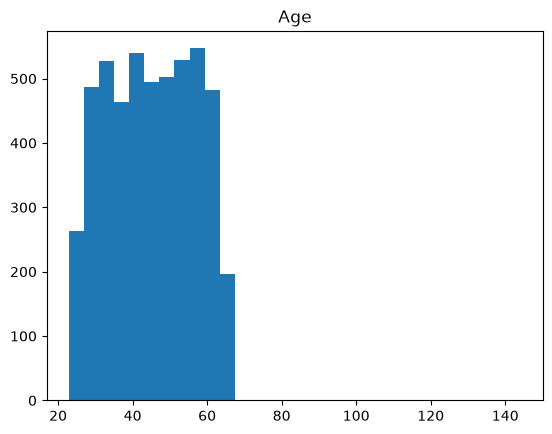

Experience
minimo: -3
maximo: 43
rango: 46
valores unicos: 47


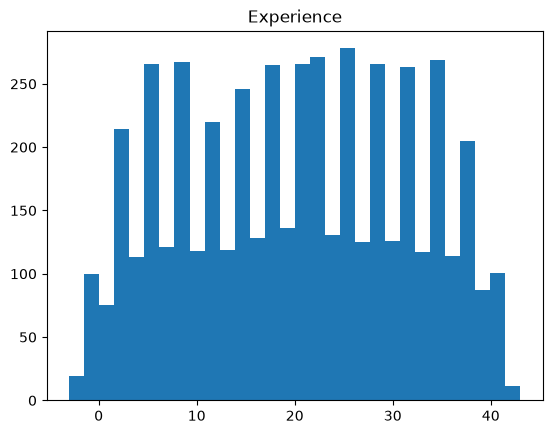

Income
minimo: 8
maximo: 224
rango: 216
valores unicos: 162


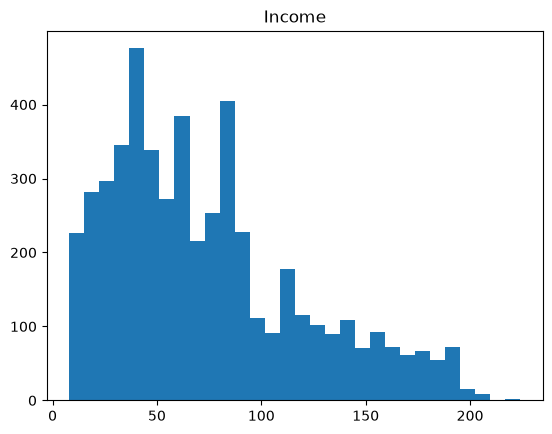

ZIP Code
minimo: 9307
maximo: 96651
rango: 87344
valores unicos: 468


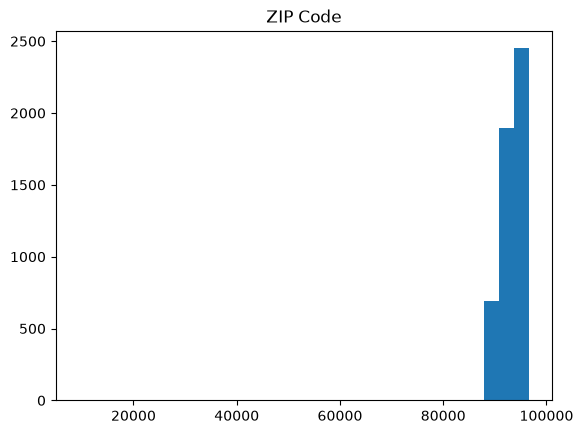

Family
minimo: -3
maximo: 4
rango: 7
valores unicos: 6


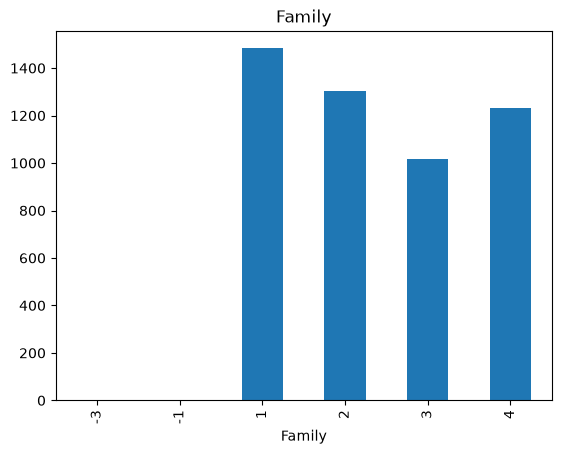

CCAvg
minimo: 0.0
maximo: 10.0
rango: 10.0
valores unicos: 108


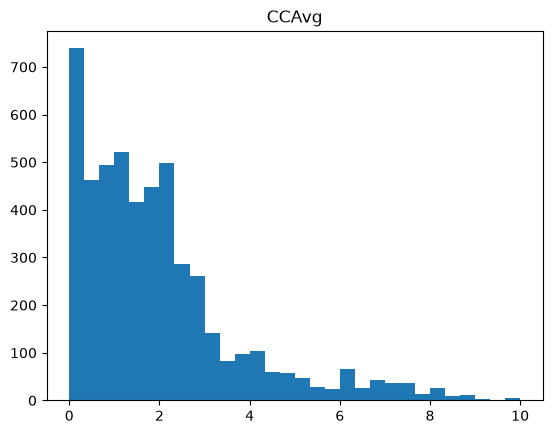

Education
minimo: 1.0
maximo: 7.3
rango: 6.3
valores unicos: 4


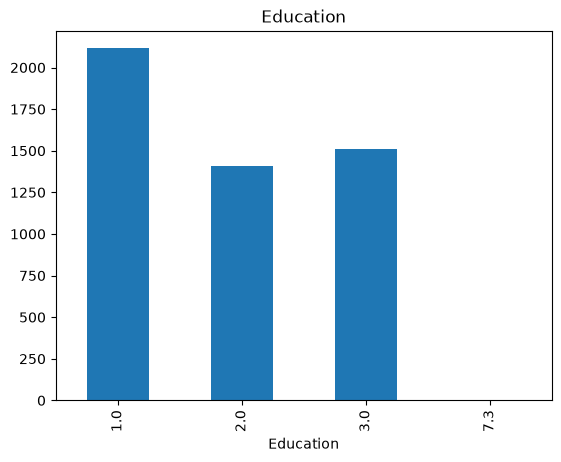

Mortgage
minimo: 0
maximo: 635
rango: 635
valores unicos: 347


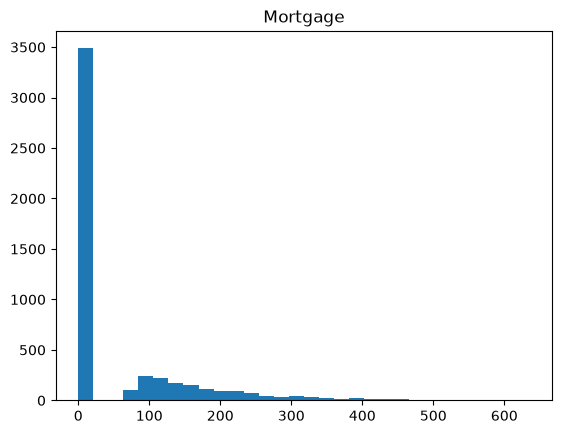

In [ ]:
# rango, valores unicos y grafica de cada variable numerica
for col in loan_df.select_dtypes('number').columns:
    print(col)
    print('minimo:', loan_df[col].min())
    print('maximo:', loan_df[col].max())
    print('rango:', loan_df[col].max() - loan_df[col].min())
    print('valores unicos:', loan_df[col].nunique())

    plt.figure()
    if loan_df[col].nunique() <= 20:
        loan_df[col].value_counts().sort_index().plot(kind='bar')
    else:
        plt.hist(loan_df[col], bins=30)
    plt.title(col)
    plt.show()

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [ ]:
loan_df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


In [ ]:

loan_df[loan_df['Age'] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [ ]:
# limite de edad: media + 2 desviaciones estandar
media = loan_df['Age'].mean()
desv = loan_df['Age'].std()
limite = media + 2 * desv
print('media:', media)
print('desviacion estandar:', desv)
print('limite:', limite)

media: 45.41135596585269
desviacion estandar: 11.646805055385956
limite: 68.7049660766246


In [ ]:
loan_df[loan_df['Age'] > limite]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [ ]:
loan_df = loan_df[loan_df['Age'] <= limite]
print(len(loan_df))

5034


In [ ]:
# experiencia negativa
loan_df[loan_df['Experience'] < 0]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
89,25,-1,113,94303,4,2.30,3.0,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.70,2.0,0,0,No,0,No,0
315,24,-2,51,90630,3,0.30,3.0,0,0,No,No,1,0
451,28,-2,48,94132,2,1.75,3.0,89,0,No,0,1,No
524,24,-1,75,93014,4,0.20,1.0,0,0,No,No,Yes,0
536,25,-1,43,92173,3,2.40,2.0,176,No,No,0,1,0
540,25,-1,109,94010,4,2.30,3.0,314,0,No,No,1,0
576,25,-1,48,92870,3,0.30,3.0,0,0,No,0,0,1
583,24,-1,38,95045,2,1.70,2.0,0,No,No,No,Yes,0


In [ ]:
loan_df = loan_df[loan_df['Experience'] >= 0]
print(len(loan_df))

4981


In [ ]:

loan_df[loan_df['Family'] <= 0]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
15,60,30,22,95054,-1,1.5,3.0,0,0,No,0,Yes,Yes
3000,40,14,164,94720,-3,4.3,2.0,0,1,No,No,No,No


In [ ]:
loan_df = loan_df[loan_df['Family'] > 0]
print(len(loan_df))

4979


In [ ]:

loan_df['Education'].value_counts()

Education
1.0    2098
3.0    1487
2.0    1393
7.3       1
Name: count, dtype: int64

In [ ]:
loan_df = loan_df[loan_df['Education'].isin([1, 2, 3])]
print(len(loan_df))

4978


In [ ]:

loan_df[loan_df['ZIP Code'] < 10000]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
384,51,25,21,9307,4,0.6,3.0,0,No,0,0,1,Yes


In [ ]:
loan_df = loan_df[loan_df['ZIP Code'] >= 10000]
print(len(loan_df))

4977


In [ ]:
# reviso que no haya otros valores raros
print((loan_df['Income'] <= 0).sum())
print((loan_df['CCAvg'] < 0).sum())
print((loan_df['Mortgage'] < 0).sum())
print((loan_df['Experience'] > loan_df['Age']).sum())

0
0
0
0


In [ ]:
eliminados = 5037 - len(loan_df)
print('eliminados:', eliminados)
print('porcentaje:', eliminados / 5037 * 100)

eliminados: 60
porcentaje: 1.1911852293031566


**Respuesta:**

* **Age:** se eliminaron 3 registros (123, 144 y 130 años). Use como límite la media + 2 desviaciones estándar (45.41 + 2 × 11.65 = 68.7 años). Además no tiene sentido que un cliente tenga más de 120 años. Se que la instrucción eran 100 años pero quería mostrar que la selección de los datos se podía llegar al mismo criterio usando un filtro basado en un mini analisis de la distribución de los datos.
* **Experience:** se eliminaron 53 registros con valores negativos (-1, -2 y -3). Los años de experiencia no pueden ser negativos.
* **Family:** se eliminaron 2 registros (-1 y -3). Una familia tiene al menos 1 integrante.
* **Education:** se eliminó 1 registro con valor 7.3. Solo existen los niveles 1, 2 y 3.
* **ZIP Code:** se eliminó 1 registro con el código 9307, que solo tiene 4 dígitos. Los códigos postales tienen 5 dígitos.
* En Income, CCAvg y Mortgage no hay valores negativos, y ningún cliente tiene más experiencia que edad.

En total se eliminaron **60 registros de 5,037, que es un poco más del 1 %**.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [ ]:
loan_df.describe(include='object')

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4977,4977,4977,4977,4977
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628


In [ ]:
print(loan_df['Personal Loan'].value_counts())
print(loan_df['Securities Account'].value_counts())
print(loan_df['CD Account'].value_counts())
print(loan_df['Online'].value_counts())
print(loan_df['CreditCard'].value_counts())

Personal Loan
0      3475
No     1017
Yes     368
1       117
Name: count, dtype: int64
Securities Account
No     2693
0      1765
Yes     390
1       129
Name: count, dtype: int64
CD Account
No     2462
0      2212
1       163
Yes     140
Name: count, dtype: int64
Online
Yes    1700
No     1628
1      1275
0       374
Name: count, dtype: int64
CreditCard
0      2628
Yes     907
No      885
1       557
Name: count, dtype: int64


In [ ]:
# cambiar Yes/No y '1'/'0' a 1 y 0
loan_df = loan_df.replace({'Yes': 1, 'No': 0, '1': 1, '0': 0})

print(loan_df['Personal Loan'].value_counts())
print(loan_df['Securities Account'].value_counts())
print(loan_df['CD Account'].value_counts())
print(loan_df['Online'].value_counts())
print(loan_df['CreditCard'].value_counts())

Personal Loan
0    4492
1     485
Name: count, dtype: int64
Securities Account
0    4458
1     519
Name: count, dtype: int64
CD Account
0    4674
1     303
Name: count, dtype: int64
Online
1    2975
0    2002
Name: count, dtype: int64
CreditCard
0    3513
1    1464
Name: count, dtype: int64


C:\Users\jose_\AppData\Local\Temp\ipykernel_17020\3258783400.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  loan_df = loan_df.replace({'Yes': 1, 'No': 0, '1': 1, '0': 0})


**Respuesta:** Las cinco columnas de texto tienen 4 categorías cada una, aunque en realidad son binarias: mezclan `Yes`/`No` con `'1'`/`'0'`. Se unificaron con el mapeo `Yes`→1, `No`→0, `'1'`→1, `'0'`→0, de acuerdo con la descripción de la libreta (1 = sí, 0 = no). Ahora cada columna tiene sólo los valores 0 y 1.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [ ]:
loan_df.duplicated().sum()

np.int64(36)

In [ ]:
loan_df = loan_df.drop_duplicates()
loan_df = loan_df.reset_index(drop=True)
print(len(loan_df))
print('eliminados en total:', 5037 - len(loan_df))
print('porcentaje:', (5037 - len(loan_df)) / 5037 * 100)

4941
eliminados en total: 96
porcentaje: 1.9058963668850508


In [ ]:
loan_df.tail()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
4936,29,3,40,92697,1,1.9,3.0,0,0,0,0,1,0
4937,30,4,15,92037,4,0.4,1.0,85,0,0,0,1,0
4938,63,39,24,93023,2,0.3,3.0,0,0,0,0,0,0
4939,65,40,49,90034,3,0.5,2.0,0,0,0,0,1,0
4940,28,4,83,92612,3,0.8,1.0,0,0,0,0,1,1


**Respuesta:** Se encontraron **36 registros duplicados** (filas idénticas en todas las columnas con distinto `ID`) y se eliminaron conservando la primera aparición. Se detectaron después de unificar los valores binarios, así que se cuentan también los duplicados que antes sólo diferían en el formato (`Yes` vs `1`). 

Se reinició el índice con `reset_index(drop=True)` para tener una secuencia continua de 0 a 4,940. Considerando todas las eliminaciones hechas hasta aquí, se quitaron **96 registros (1.91 %)** y quedan **4,941**.


5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [ ]:
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(str)
loan_df['Education'] = loan_df['Education'].astype(int)
loan_df['Education'] = pd.Categorical(loan_df['Education'], categories=[1, 2, 3], ordered=True)
loan_df['Personal Loan'] = loan_df['Personal Loan'].astype('category')
loan_df['Securities Account'] = loan_df['Securities Account'].astype('category')
loan_df['CD Account'] = loan_df['CD Account'].astype('category')
loan_df['Online'] = loan_df['Online'].astype('category')
loan_df['CreditCard'] = loan_df['CreditCard'].astype('category')

In [ ]:
num_cols = ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
cat_cols = ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4941 entries, 0 to 4940
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Age                 4941 non-null   int64   
 1   Experience          4941 non-null   int64   
 2   Income              4941 non-null   int64   
 3   ZIP Code            4941 non-null   object  
 4   Family              4941 non-null   int64   
 5   CCAvg               4941 non-null   float64 
 6   Education           4941 non-null   category
 7   Mortgage            4941 non-null   int64   
 8   Personal Loan       4941 non-null   category
 9   Securities Account  4941 non-null   category
 10  CD Account          4941 non-null   category
 11  Online              4941 non-null   category
 12  CreditCard          4941 non-null   category
dtypes: category(6), float64(1), int64(5), object(1)
memory usage: 300.0+ KB


**Respuesta:**
* `num_cols` = `Age`, `Experience`, `Income`, `Family`, `CCAvg`, `Mortgage` (6 variables).
* `cat_cols` = `ZIP Code` (nominal), `Education` (ordinal 1 < 2 < 3) y las binarias `Personal Loan`, `Securities Account`, `CD Account`, `Online`, `CreditCard` (7 variables).

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [ ]:
loan_df[num_cols].describe()

,Age,Experience,Income,Family,CCAvg,Mortgage
count,4941.000000,4941.000000,4941.000000,4941.000000,4941.000000,4941.000000
mean,45.560210,20.335357,73.826553,2.391621,1.935855,56.663631
std,11.315617,11.308351,46.106768,1.148244,1.748406,101.875349
min,24.000000,0.000000,8.000000,1.000000,0.000000,0.000000
25%,36.000000,11.000000,39.000000,1.000000,0.700000,0.000000
50%,46.000000,20.000000,64.000000,2.000000,1.500000,0.000000
75%,55.000000,30.000000,98.000000,3.000000,2.600000,101.000000
max,67.000000,43.000000,224.000000,4.000000,10.000000,635.000000


In [ ]:
print('Asimetria')
print(loan_df[num_cols].skew())
print()
print('Curtosis')
print(loan_df[num_cols].kurt())

Asimetria
Age          -0.022754
Experience   -0.015216
Income        0.841991
Family        0.159463
CCAvg         1.594670
Mortgage      2.103865
dtype: float64

Curtosis
Age          -1.161599
Experience   -1.134857
Income       -0.046164
Family       -1.403842
CCAvg         2.635545
Mortgage      4.760021
dtype: float64


**Clasificación** (criterio: |asimetría| < 0.5 se considera simétrica; exceso de curtosis ≈ 0 es mesocúrtica, > 0 leptocúrtica y < 0 platicúrtica):

* **`Age`**: asimetría = -0.02 → **aproximadamente simétrica**; curtosis = -1.16 → **platicúrtica** (distribución aplanada, con colas más ligeras que la normal, parecida a una uniforme entre 24 y 67 años).
* **`Income`**: asimetría = 0.84 → **asimétrica positiva moderada** (cola hacia la derecha: pocos clientes con ingresos muy altos); curtosis = -0.05 → **mesocúrtica**.
* **`Mortgage`**: asimetría = 2.10 → **fuertemente asimétrica positiva**; curtosis = 4.76 → **leptocúrtica** (pico muy alto en 0 y cola larga hacia valores grandes).

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

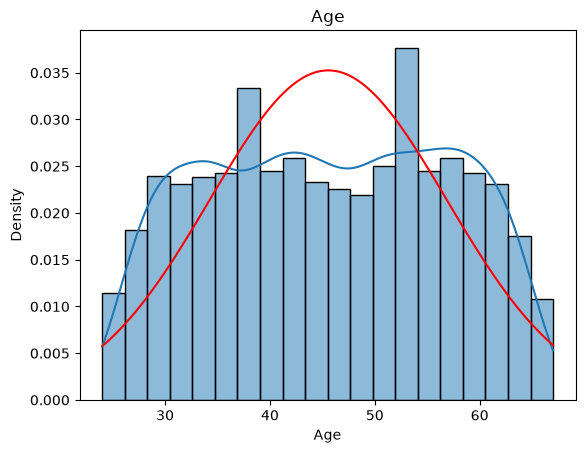

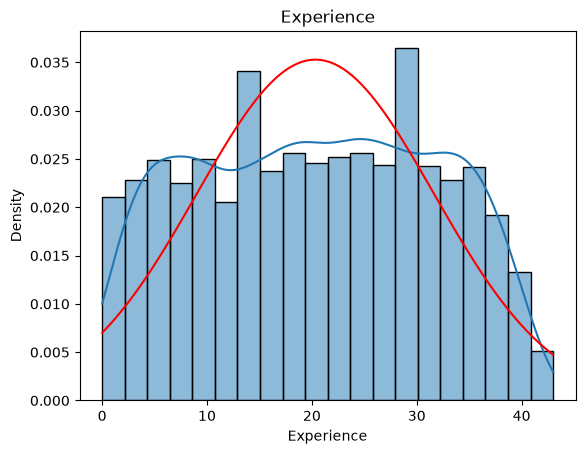

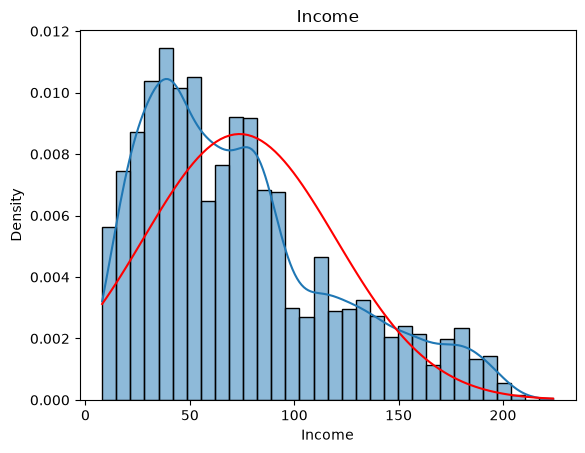

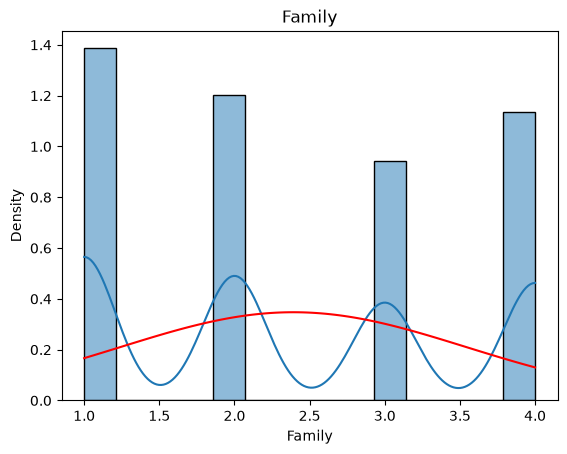

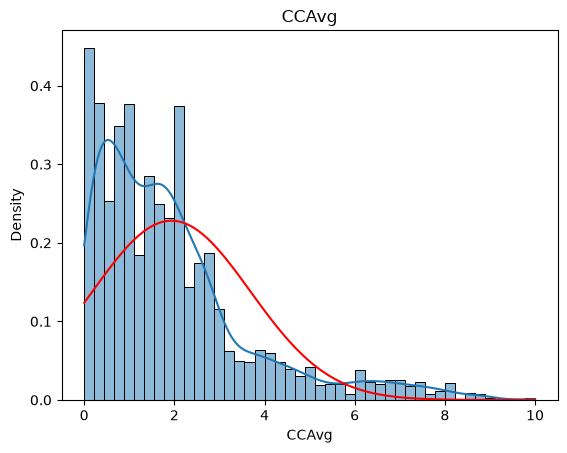

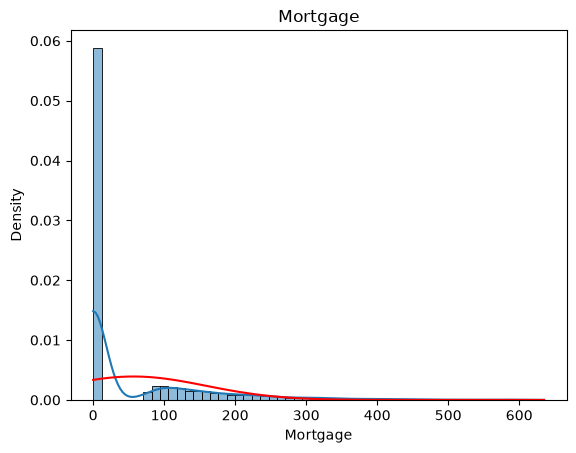

In [ ]:
for col in num_cols:
    plt.figure()
    sns.histplot(loan_df[col], kde=True, stat='density')
    x = np.linspace(loan_df[col].min(), loan_df[col].max(), 100)
    plt.plot(x, norm.pdf(x, loan_df[col].mean(), loan_df[col].std()), color='red')
    plt.title(col)
    plt.show()

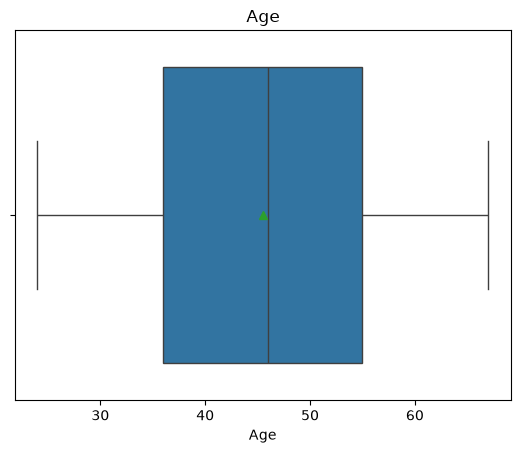

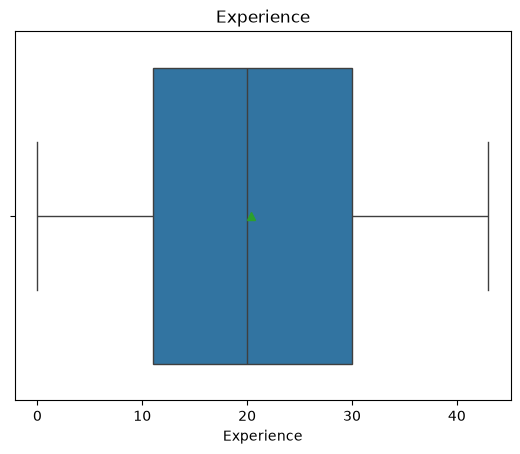

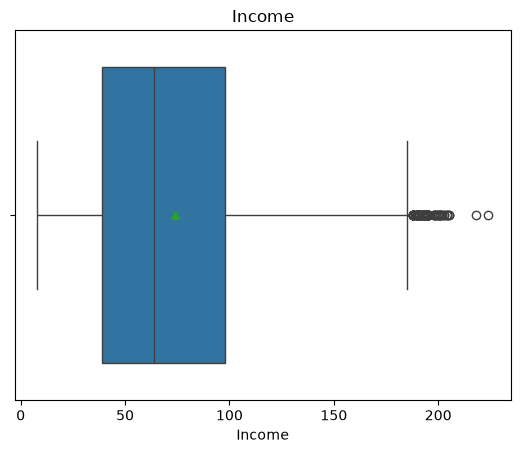

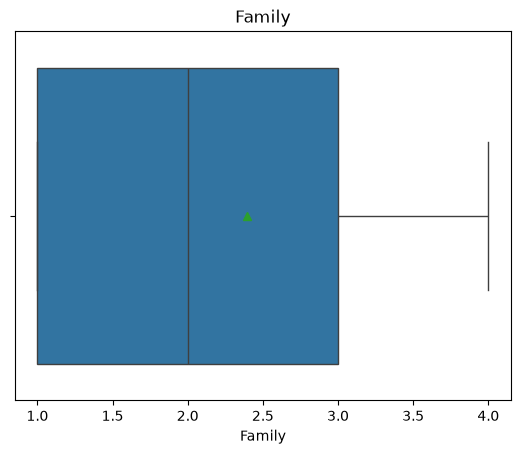

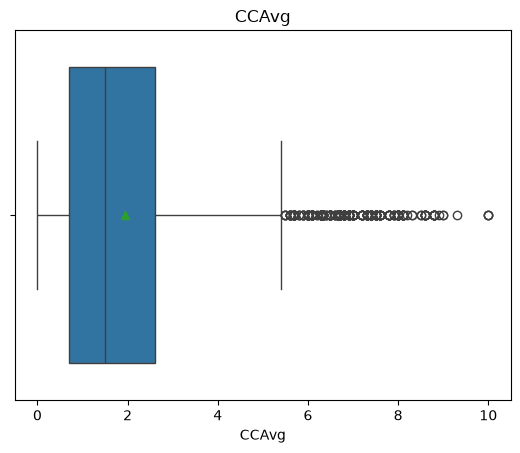

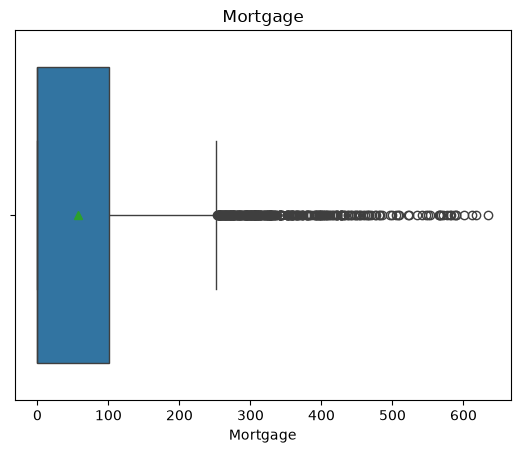

In [ ]:
for col in num_cols:
    plt.figure()
    sns.boxplot(x=loan_df[col], showmeans=True)
    plt.title(col)
    plt.show()

In [ ]:
print('Media')
print(loan_df[num_cols].mean())
print()
print('Mediana')
print(loan_df[num_cols].median())

Media
Age           45.560210
Experience    20.335357
Income        73.826553
Family         2.391621
CCAvg          1.935855
Mortgage      56.663631
dtype: float64

Mediana
Age           46.0
Experience    20.0
Income        64.0
Family         2.0
CCAvg          1.5
Mortgage       0.0
dtype: float64


**Comparación de los histogramas con los valores numéricos:**
* **`Age`**: el histograma es casi plano entre 30 y 60 años, sin un pico central marcado, y la KDE queda por debajo de la normal en el centro y por encima en los extremos. Coincide con lo esperado: simétrica y platicúrtica.
* **`Income`**: la mayor concentración está entre 20 y 90 mil USD y hay una cola larga hacia la derecha hasta 224. Coincide con la asimetría positiva; la curtosis cercana a 0 se refleja en que la dispersión es similar a la de la normal, aunque la forma no es normal.
* **`Mortgage`**: hay un pico enorme en 0 (más de la mitad de los clientes no tiene hipoteca) y el resto se reparte en una cola larga hasta 635. Coincide con la fuerte asimetría positiva y la alta curtosis; la curva normal no describe para nada estos datos.

**Media vs. mediana (boxplots):**
* En `Age`, `Experience` y `Family` la media y la mediana son casi iguales: distribuciones aproximadamente simétricas.
* En `Income` (media 73.8 > mediana 64), `CCAvg` (1.94 > 1.5) y sobre todo `Mortgage` (56.7 > 0), **la media está a la derecha de la mediana**. Los valores extremos altos (atípicos en el boxplot) jalan la media hacia arriba, lo que indica **asimetría positiva**.
* En general, si media > mediana el sesgo es positivo (cola a la derecha); si media < mediana el sesgo es negativo (cola a la izquierda), y si son casi iguales la distribución es aproximadamente simétrica. Los resultados coinciden con los signos de asimetría calculados en el ejercicio 6.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [ ]:
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


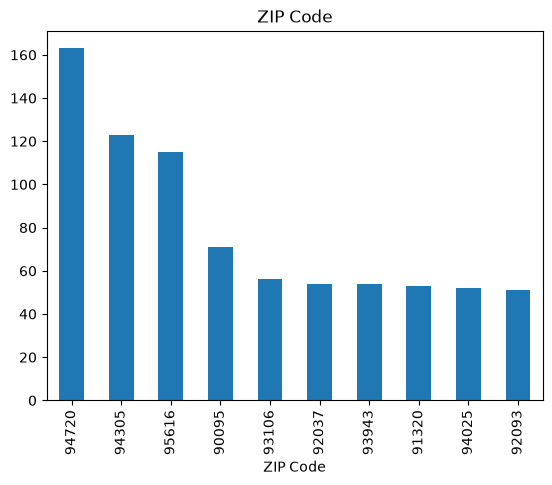

In [ ]:
# ZIP Code tiene muchos valores, solo los 10 mas comunes
loan_df['ZIP Code'].value_counts().head(10).plot(kind='bar')
plt.title('ZIP Code')
plt.show()

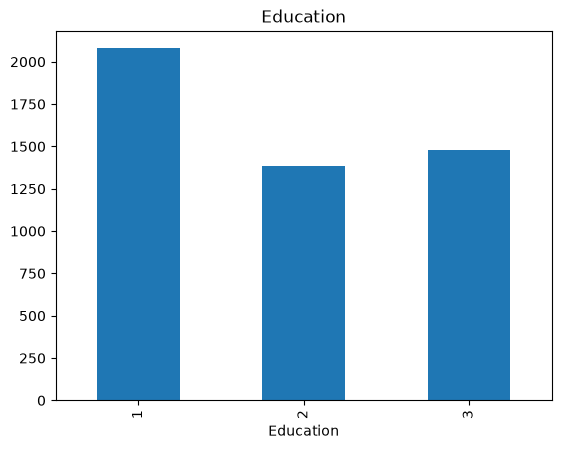

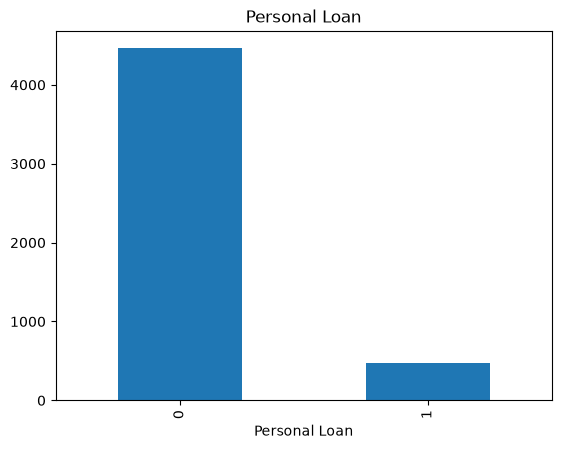

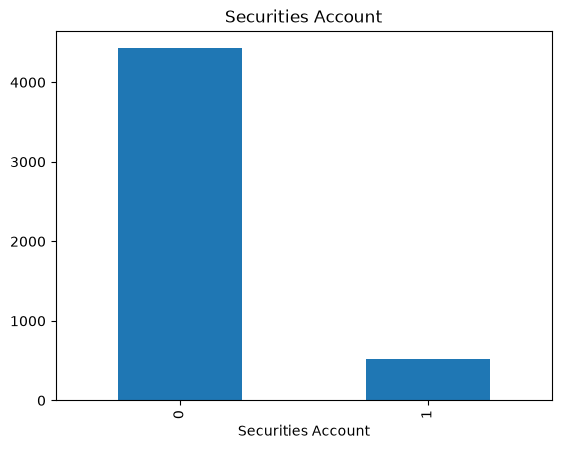

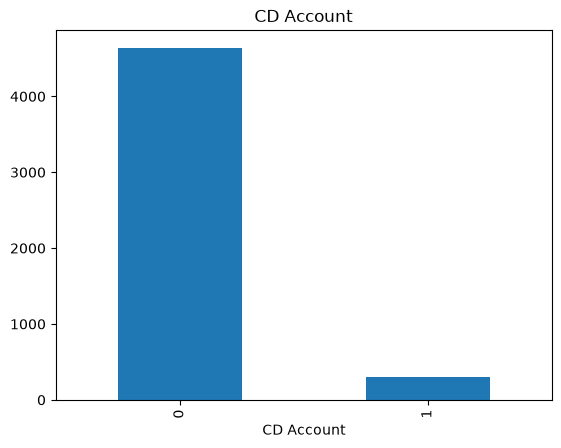

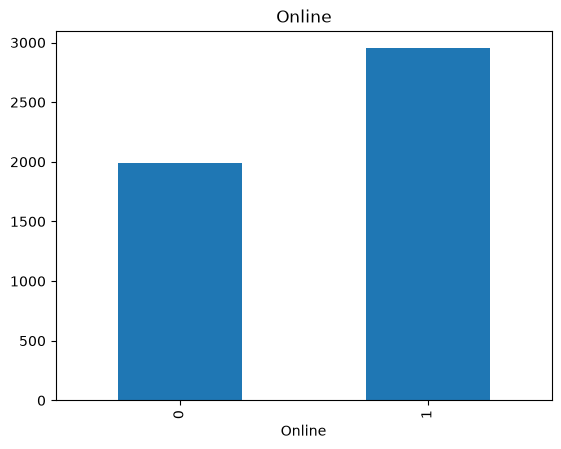

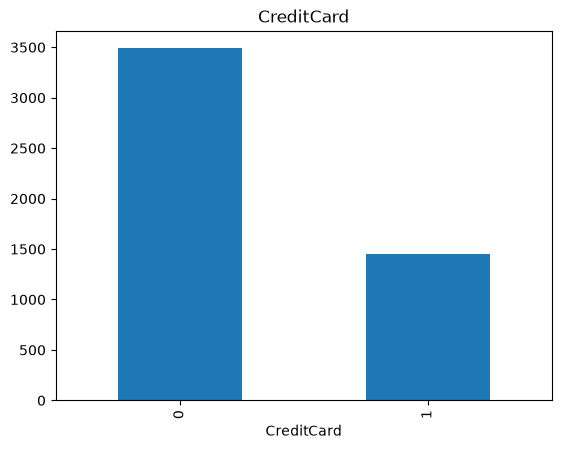

In [ ]:
for col in ['Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']:
    loan_df[col].value_counts().sort_index().plot(kind='bar')
    plt.title(col)
    plt.show()

**Observaciones:** `ZIP Code` tiene alta cardinalidad (467 códigos distintos), por eso sólo se grafican los 10 más frecuentes; el más común es 94720 (163 clientes). En `Education` predomina el nivel 1 (graduado). La variable objetivo `Personal Loan` está **muy desbalanceada**: sólo 479 clientes (≈ 9.7 %) aceptaron el préstamo. Hay que tomarlo en cuenta al construir el modelo.

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

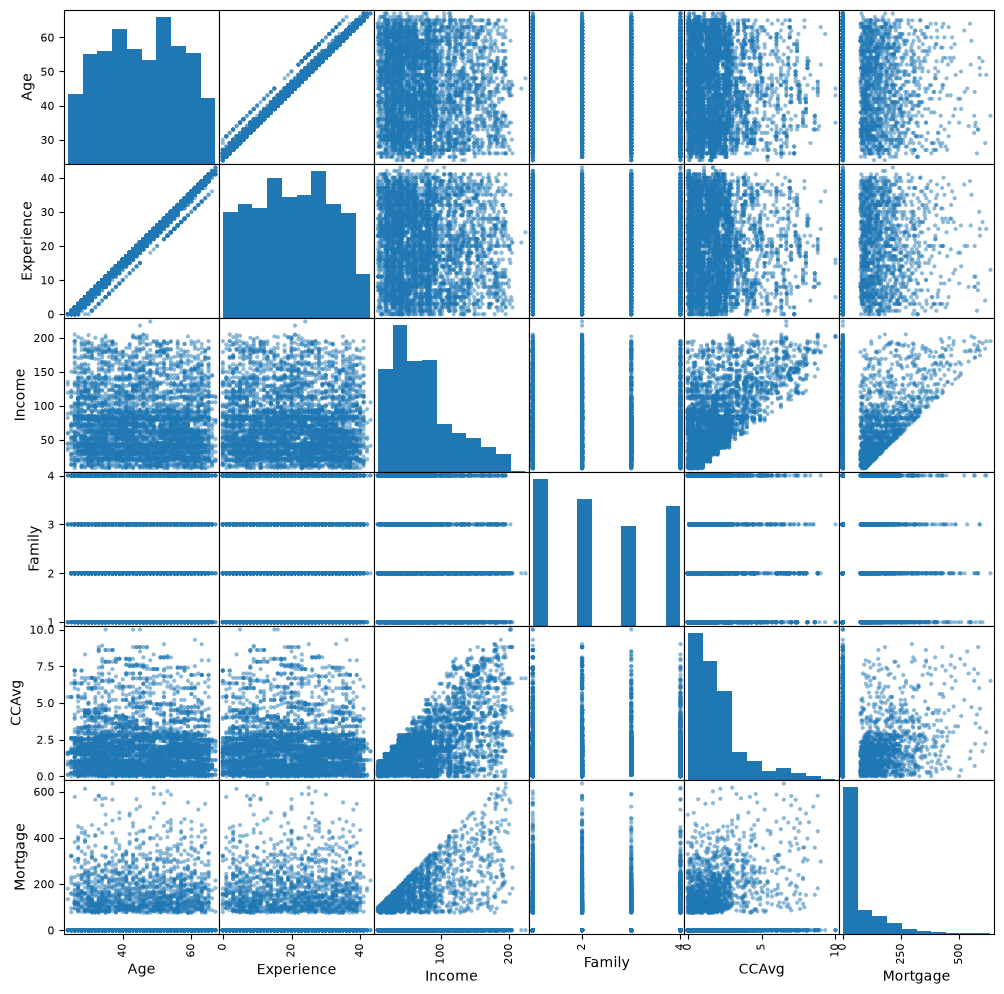

In [ ]:
pd.plotting.scatter_matrix(loan_df[num_cols], figsize=(12, 12))
plt.show()

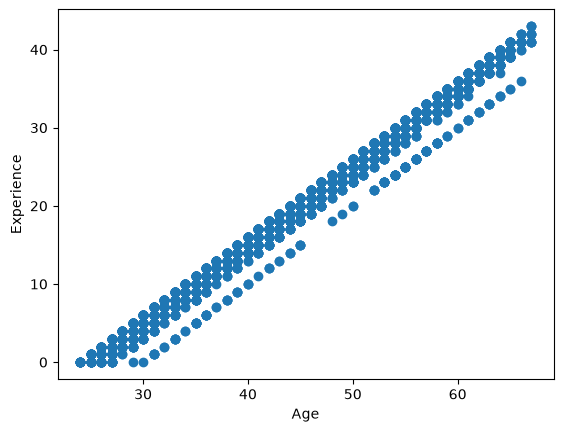

In [ ]:
plt.scatter(loan_df['Age'], loan_df['Experience'])
plt.xlabel('Age')
plt.ylabel('Experience')
plt.show()

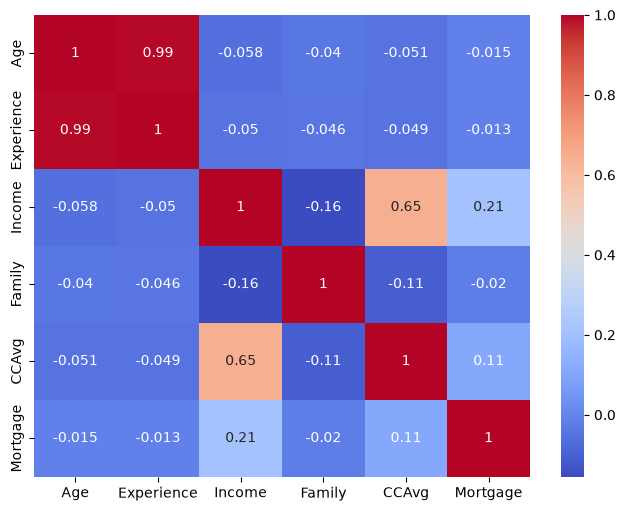

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(loan_df[num_cols].corr(), annot=True, cmap='coolwarm')
plt.show()

**Par seleccionado: `Age` vs `Experience`.** En la scatter matrix se ve una relación lineal positiva casi perfecta: los puntos forman una franja muy delgada y la experiencia aumenta casi uno a uno con la edad (Experience ≈ Age - 25). También se aprecia una tendencia positiva entre `Income` y `CCAvg`: a mayor ingreso, mayor gasto con tarjeta lo cual es  una obiedad pero tiene más dispersión. 

**Mapa de calor:** la correlación de Pearson entre `Age` y `Experience` es **0.99**, lo que coincide con lo esperado: una relación lineal positiva prácticamente perfecta. Esto implica redundancia (multicolinealidad), así que en el modelo podría bastar con una de las dos. `Income` y `CCAvg` tienen 0.65, una correlación positiva moderada, congruente con la nube dispersa observada. `Income` también se relaciona débilmente con `Mortgage` (~0.2), y el resto de los pares tiene correlaciones cercanas a 0.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


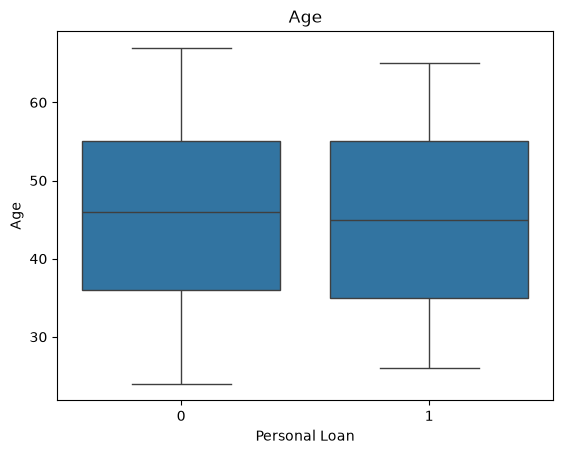

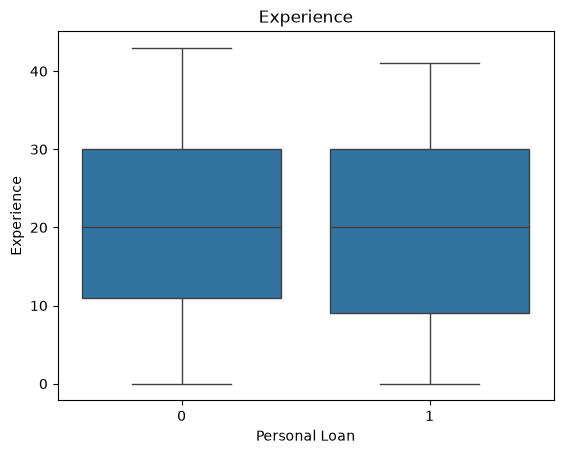

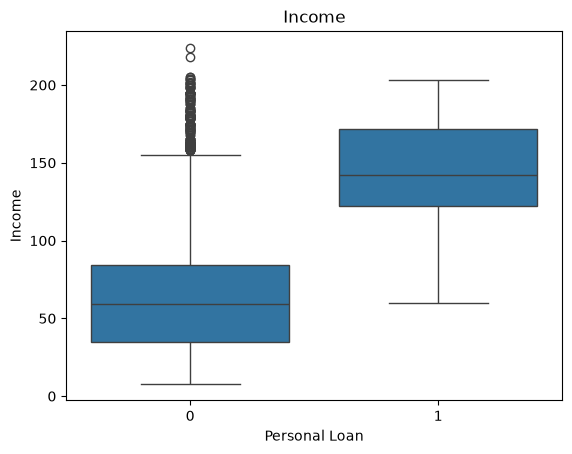

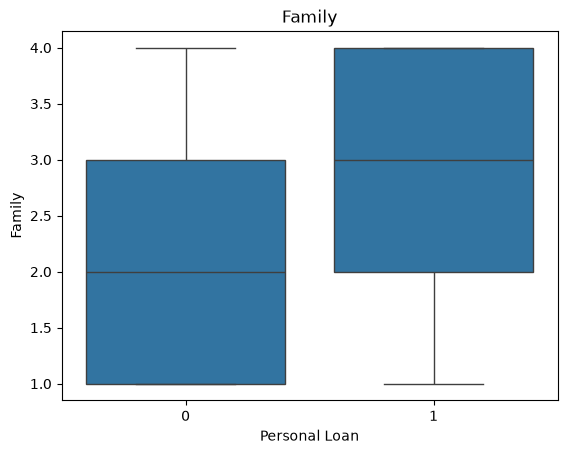

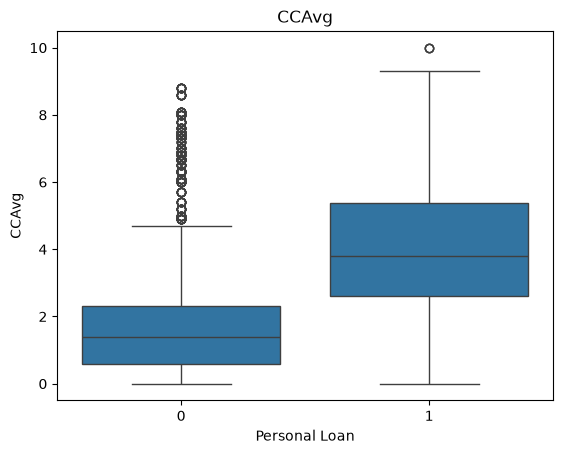

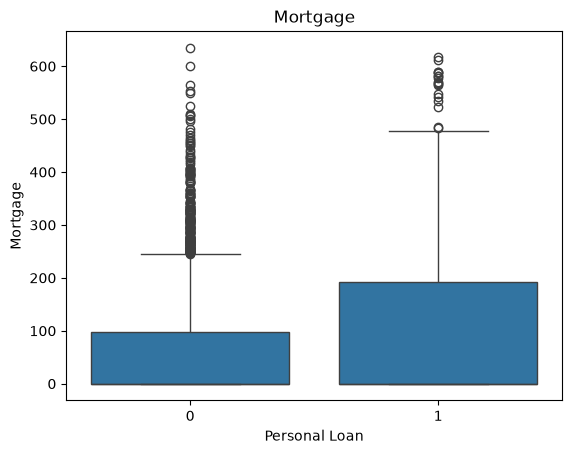

In [ ]:
for col in num_cols:
    sns.boxplot(x='Personal Loan', y=col, data=loan_df)
    plt.title(col)
    plt.show()

In [ ]:
loan_df.groupby('Personal Loan')[num_cols].median()

C:\Users\jose_\AppData\Local\Temp\ipykernel_17020\1652570880.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  loan_df.groupby('Personal Loan')[num_cols].median()


,Age,Experience,Income,Family,CCAvg,Mortgage
Personal Loan,,,,,,
0,46.0,20.0,59.0,2.0,1.4,0.0
1,45.0,20.0,142.0,3.0,3.8,0.0


Personal Loan         0         1
Education                        
1              0.955267  0.044733
2              0.869314  0.130686
3              0.861205  0.138795


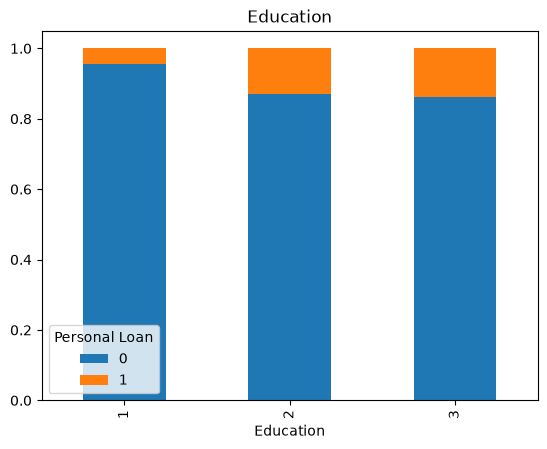

Personal Loan              0         1
Securities Account                    
0                   0.905332  0.094668
1                   0.883495  0.116505


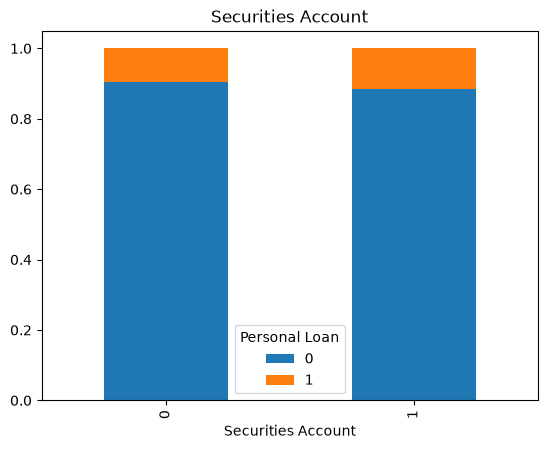

Personal Loan         0         1
CD Account                       
0              0.926940  0.073060
1              0.534884  0.465116


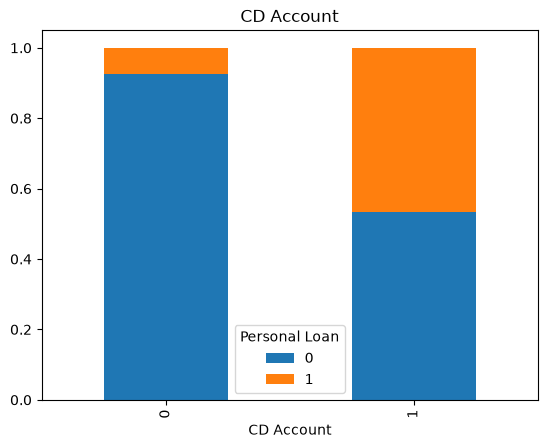

Personal Loan         0         1
Online                           
0              0.905528  0.094472
1              0.901389  0.098611


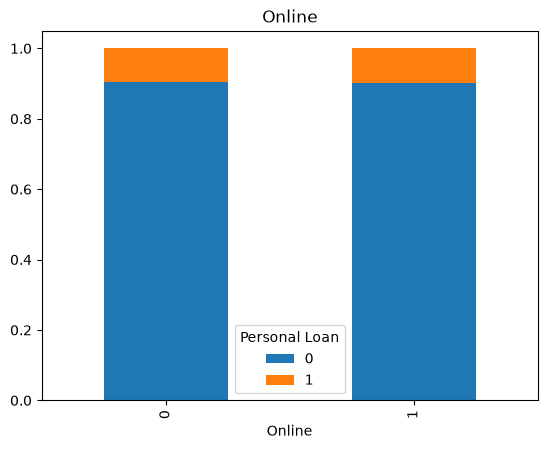

Personal Loan         0         1
CreditCard                       
0              0.903697  0.096303
1              0.901515  0.098485


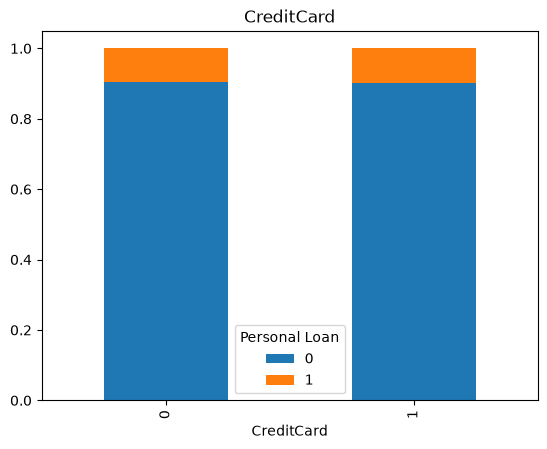

In [ ]:
for col in ['Education', 'Securities Account', 'CD Account', 'Online', 'CreditCard']:
    tabla = pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize='index')
    print(tabla)
    tabla.plot(kind='bar', stacked=True)
    plt.title(col)
    plt.show()

**Hallazgos en las variables numéricas:**
* **`Income`** es la que mejor separa a los grupos: la mediana de ingreso de quienes aceptaron el préstamo es notoriamente mayor de quienes no lo aceptaron, y las cajas casi no se traslapan.
* **`CCAvg`** muestra un patrón similar.
* `Mortgage` es mayor en promedio en quienes aceptaron, mientras que `Age` y `Experience` tienen distribuciones prácticamente iguales en ambos grupos, por lo que aportan poca información para predecir `Personal Loan`.

**Hallazgos en las variables categóricas:**
* **`CD Account`** es la más relevante, practicamente la mitad de los clientes con cuenta de cd aceptó el préstamo, contra sólo 7 % de quienes no la tienen.
* **`Education`**: la tasa de aceptación sube notoriamente entre el nivel 1 a los niveles 2 y 3. Aquí el cambio relevante es de 1 a 2, por lo que sería de interes analizar que caractersiticas tienen las personas con educación mayor o igual a 2 ya que estro podría ayudar a identificar variables de interes para la predicción de acpetar el prestamo..

* `Securities Account`, `Online` y `CreditCard` tienen tasas casi idénticas (rondan el rango del 9-12 %) en ambas categorías, así que por sí solas no parecen influir en la aceptación del préstamo.

---
**Declaración de uso de IA**

*   Anthropic. (2026). *Claude (Opus 5.5)* [Modelo de lenguaje grande], utilizado en la aplicación de Claude para la generación y el refinamiento del código y la explicación de conceptos, y en Claude Code para la revisión. https://claude.ai/

La herramienta se usó para corregir algunas partes de mi trabajo, detectar errores conceptuales, de sintaxis, validar mis respuestas y mejorar alguos elementos del código. El notebook se desarrolló en Cursor (VSC) como IDE. 

En las graficas me apoye completamente en Claude para la generación de los parametros ya que al intentar agruparlos a mano me resultó muy complicado encontrar proporciones que fueran utiles. Claude también mejoro el estilo y la selección de colores así como la generación de parametros para los titulos, margenes etc. 